In [67]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math
import copy
from collections import deque

# 1. Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [68]:
image = cv2.imread('images/sar_1.jpg')
image_gray = cv2.imread('images/sar_1.jpg', cv2.IMREAD_GRAYSCALE)

In [69]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [70]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask

    return mask*255

15
33
51
69
87
105
123
141
159
177
195
212
231
249
267
283
302
321
339
357
376
393
411
429
447
465
483
501
517
529
535
349
342
342
338
337
330
322
322
319
312
316
306
301
292
290
288
286
281
277
274
270
262
258
251
246
237
231
224
217
214
210
203
198
192
185
178
169
165
160
154
151
148
144
138
134
155
125
120
116
111
48
45
44
43
42
39
37
36
35
36
34
33
31
30
29
28
25
23
22
21
18
16
15
12
10
6
2
0


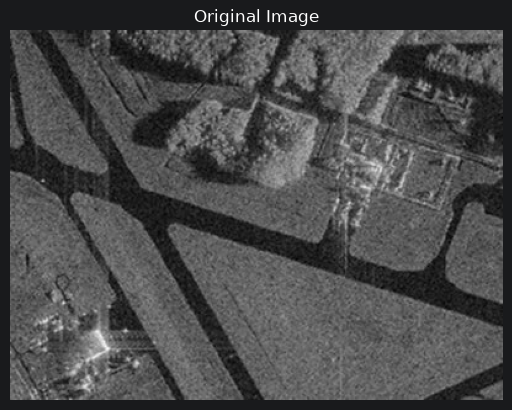

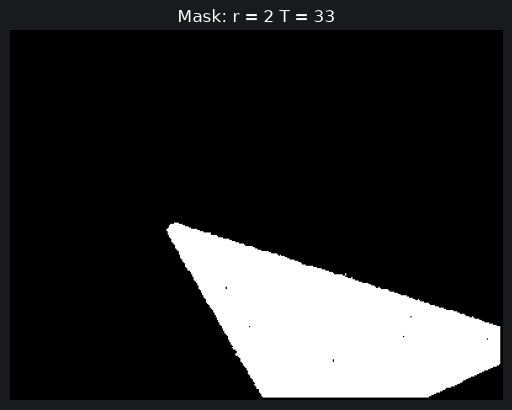

In [71]:
seed_point = (235, 235)
mask = region_growing(image_gray, seed_point, homo_average, 2, 33)
plt.imshow(image_gray, cmap='gray')
plt.axis('off')
plt.title('Original Image')
plt.show()
plt.imshow(mask, cmap='gray')
plt.axis('off')
plt.title(f'Mask: r = {2} T = {33}')
plt.show()

# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [72]:
z = np.float32(image_gray.reshape((-1,3)))
K = 3
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
ret, label, center = cv2.kmeans(z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
center = np.uint8(center)
res = center[label.flatten()]
res2 = res.reshape((image_gray.shape))

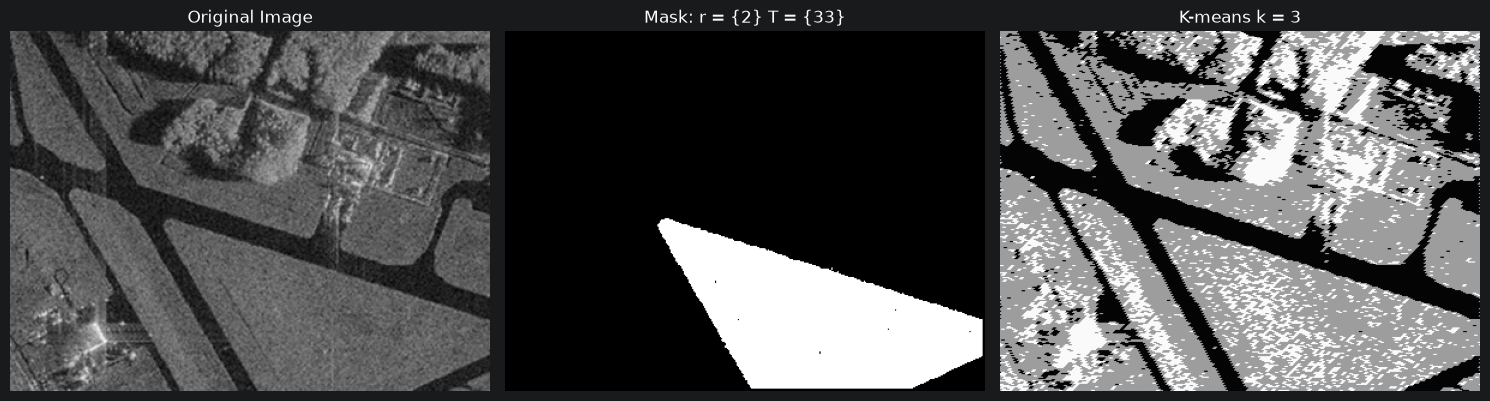

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title(f'Original Image')
axes[0].axis('off')

axes[1].imshow(mask, cmap='gray')
axes[1].set_title('Mask: r = {2} T = {33}')
axes[1].axis('off')

axes[2].imshow(res2, cmap='gray')
axes[2].set_title(f'K-means k = {3}')
axes[2].axis('off')

plt.tight_layout()
plt.show()

# 3. Применить алгоритм сегментации watershed + distance_transform для задачи подсчета пальмовых деревьев.

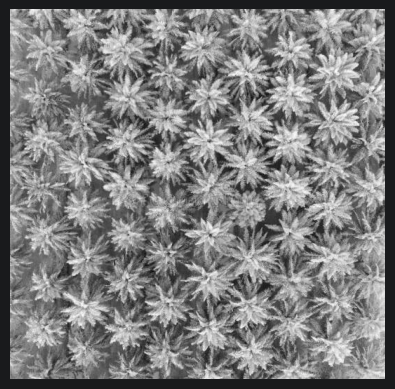

In [74]:
palm = cv2.imread("images/palm_1.JPG")
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
plt.imshow(palm_gray, cmap='gray')
plt.axis('off')
plt.show()

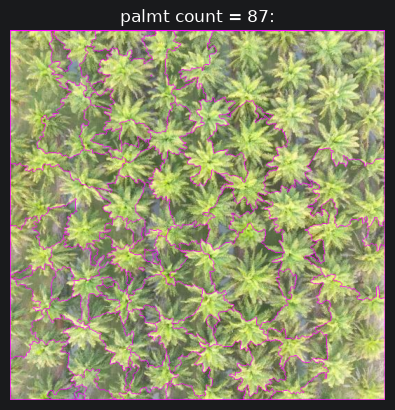

In [75]:
palm_gb = cv2.GaussianBlur(palm_gray, (11, 11), 0)
ret, thresh = cv2.threshold(palm_gb, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
ret, sure_fg = cv2.threshold(dist, 0.6 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

ret, mark = cv2.connectedComponents(sure_fg)
mark = cv2.watershed(palm, mark.astype(np.int32))
count = len(np.unique(mark)) - 1
palm_res = palm.copy()
palm_res[mark == -1] = [255, 0, 255]

plt.imshow(cv2.cvtColor(palm_res, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f'palmt count = {count}:')
plt.show()